### Multiple vehicle impact

In [1]:
# %% allow reloading of modules
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import sys
import os
pd.options.display.max_columns = None
pd.options.display.max_rows = None

In [3]:
#import sys
#sys.path.insert(0, '< your path to Pycrash>')  # if not installing with pip

In [4]:
import sys
import warnings

# pycrash's models trigger many pandas SettingWithCopy/FutureWarnings; hide them to keep output readable
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*SettingWithCopy.*")
warnings.filterwarnings("ignore", message=".*copy of a slice.*")

from pandas.errors import SettingWithCopyWarning

# Suppress only the specific SettingWithCopyWarning
warnings.simplefilter(action="ignore", category=SettingWithCopyWarning)

In [5]:
# python dictionary containing vehicle specifications
import projects.data.vehicle_data_collection as veh

In [6]:
from pycrash.impact_main import Impact
from pycrash.vehicle import Vehicle

Current values for defined constants:
maximum available friction (mu_max) = 0.8
time step for vehicle motion (dt) = 0.01 s


### Create Vehicles
- all inputs entered manually for now

- Pull data from data collection
- Assign to each vehicle

In [13]:
veh1 = Vehicle('Striking', veh.vehicle_data['ChevyTahoe'])
veh1.striking = True  # <- set to striking vehicle
veh1.isTrailer = False

veh2 = Vehicle('Struck', veh.vehicle_data['TractorTrailer'])
veh2.striking = False  # <- set to struck
veh2.isTrailer = False

veh3 = Vehicle('Barrier', veh.vehicle_data['barrier'])
veh3.striking = False  # <- set to struck
veh3.isTrailer = False

Vehicle inputs for Striking applied successfully
Vehicle inputs for Struck applied successfully
Vehicle inputs for Barrier applied successfully


### Vehicle 1 inputs

In [14]:
t = [0, 0.5, 1, 1.5, 3, 4, 5, 6]
#brake = [0, 0, 0, 0, 1, 1, 1]   # <- stopped prior to contact with barrier
#brake = [0, 0, 0, 0, 0.5, 0.5, 0.5]   # <- 
#brake = [0, 0, 0, 0, 0.4, 0.4, 0.4]      # <- 
#brake = [0, 0, 0, 0, 0.3, 0.3, 0.3]      # <- 
brake = [0, 0, 0, 0, 0.1, 0.1, 0.1, 0.1]      # <- 
#brake = [0, 0, 0, 0, 0, 0.2, 0.2]      # <- 
#brake = [0, 0, 0, 0, 0, 0, 0]      # <- 
throttle = [0] * len(t)
steer = [0, -20, -20, -20, -20, -20, -20, -20]
veh1.time_inputs(t, throttle, brake, steer, show_plot=False)
veh1.vx_initial = 45

Driver inputs applied to Striking


### Vehicle 2 inputs

In [15]:
t = [0, 0.5, 1, 1.5, 3, 4, 5, 6]
brake = [0, 0, 0, 0.5, 0.5, 0.5, 0.5, 0.5]
throttle = [0] * len(t)
steer = [0, 30, 30, 30, 30, -10, -10, 0]
veh2.time_inputs(t, throttle, brake, steer, show_plot=False)
veh2.vx_initial = 35

Driver inputs applied to Struck


### Vehicle 3 inputs

In [16]:
t = [0, 6]
brake = [0] * len(t)
throttle = [0] * len(t)
steer = [0] * len(t)
veh3.time_inputs(t, throttle, brake, steer, show_plot=False)
veh3.vx_initial = 0

Driver inputs applied to Barrier


### Vehicle impact points and impact planes manually entered
- `impact_points` is a list of impacts points in the order that they will occurr in the simulation
- `edgeimpact_points` is a list of points defining the impact edge clockwise
- each impact requires a defined point and plane even if there is no change

In [20]:
# vehicle 1
veh1.impactTotal = 1  # <- number of impacts for this vehicle
# impact point = (x, y, impact plane normal angle [deg])
veh1.impact_points = [(-veh1.lcgr + 2, -veh1.width / 2, 90), (veh1.lcgf + veh1.f_hang, 0, 0)]
#veh1.impact_points = [(-veh1.lcgr + 2, -veh1.width / 2, 90), (veh1.lcgf + veh1.f_hang, veh1.width / 2, 0)] # right front corner
veh1.init_x_pos = -30
veh1.init_y_pos = 0

# vehicle 2
veh2.impactTotal = 1  # <- number of impacts for this vehicle
veh2.edgeimpact = [1]
# (right front corner, right rear corner) -> [(x1, y1, x2, y2)]
veh2.edgeimpact_points = [(veh2.lcgf + veh2.f_hang, veh2.width / 2, -veh2.lcgr - veh2.r_hang, veh2.width / 2)]
veh2.init_x_pos = -25
veh2.init_y_pos = -10
veh2.head_angle = 0

# vehicle 3
veh3.impactTotal = 1  # <- number of impacts for this vehicle
veh3.edgeimpact = [1]
# (right front corner, right rear corner) -> [(x1, y1, x2, y2)]
veh3. edgeimpact_points = [(veh3.lcgf + veh3.f_hang, veh3.width / 2, -veh3.lcgr - veh3.r_hang, veh3.width / 2)]
veh3.init_x_pos = 100
veh3.init_y_pos = -24
veh3.type = "Barrier"  # <- motion will not be calculated

### Create Impact Object
- stores vehicle data
- runs impact simulation with vehicle motion

In [21]:
impact_1 = [0, 1]
impact_2 = [0, 2]
impact_order = [impact_1, impact_2]

# inputs for each impact
impc_inputs = {0: {'vehicle_mu': 2,
                 'cor': 0.2},
               1: {'vehicle_mu': 1.5,
                 'cor': 0.0}}

In [24]:
endTime = 6
sim_defaults = {'dt_motion': 0.01,
                'mu_max': 0.55,
                'alpha_max': 0.174533,  # 10 degrees
                }
imp = Impact('test', endTime, 'IMPC', [veh1, veh2, veh3], impact_order, impc_inputs, sim_defaults)

Impact order defined as: [[0, 1], [0, 2]]
IMPC inputs defined as: {0: {'vehicle_mu': 2, 'cor': 0.2}, 1: {'vehicle_mu': 1.5, 'cor': 0.0}}
Driver input for Striking of shape = (601, 4)
Driver input for Struck of shape = (601, 4)
Driver input for Barrier of shape = (601, 4)
Predefined impact points for Striking: [x (ft), y (ft), impact plane angle (deg)] = [(-3.05, -3.2808333333333333, 90), (8.2775, 0, 0)]
Total impacts for Striking: 2
Predefined impact edge for Struck: [1]
Total impacts for Struck - total defined edges: 1
Predefined impact edge for Barrier: [1]
Total impacts for Barrier - total defined edges: 1
{0: {'impact_points': (-3.05, -3.2808333333333333, 90), 'edgeimpact_loc': 1, 'edgeimpact_points': (10.0, 5.0, -10.0, 5.0)}, 1: {'impact_points': (8.2775, 0, 0), 'edgeimpact_loc': 1, 'edgeimpact_points': (200.0, 0.5, -200.0, 0.5)}}
Impact simulation created with 3 vehicles of type IMPC
Simulation inputs: {'dt_motion': 0.01, 'mu_max': 0.55, 'alpha_max': 0.174533}


In [ ]:
imp.vehicles[0].impact_points

In [26]:
imp.show_initial_position()

### Vehicle model

In [ ]:
imp.simulate()

In [ ]:
imp.vehicles[0].impc_result

In [ ]:
imp.plot_impact(0)

In [ ]:
imp.plot_impact(1)

In [27]:
imp.plot_vehicle_motion(5, show_vector=True)

In [ ]:
len(imp.vehicles[0].p_gx)

In [ ]:
imp._impactIndex

In [ ]:
imp.plot_model(1)

In [ ]:
imp.vehicles[0].model.head()

<Axes: >

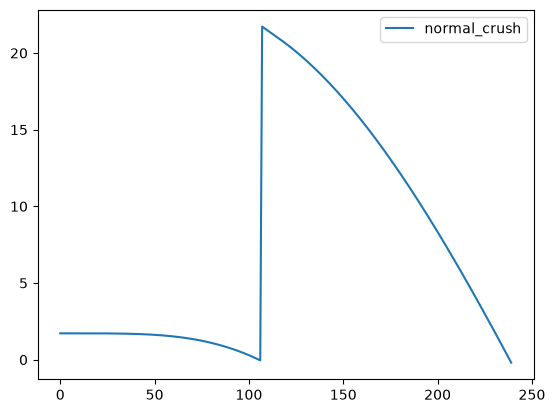

In [28]:
imp.detect_data.plot(y='normal_crush')